# Gymnasium: Training an Agent to Hit a Target

- This notebook builds a custom env from scratch, checks it, and trains an agent
  on it with `Stable-Baselines3`, with no other code than this notebook and its
  utils
- The pedagogical arc:
  - A custom `gym.Env`: spaces, `reset()`, `step()`, and seeding
  - Validate the env with `check_env()`
  - A random policy as the baseline
  - Train a `PPO` agent on a CPU in seconds
  - Compare the trained agent with the baseline
- References:
  - Custom envs: https://gymnasium.farama.org/introduction/create_custom_env/
  - Stable-Baselines3: https://stable-baselines3.readthedocs.io/

In [1]:
# Install the CPU-only `torch` first: about 200 MB and 1 to 3 minutes the first
# time. From PyPI, `stable-baselines3` would pull the CUDA build, about 1.9 GB.
!pip install -q torch==2.14.1 --index-url https://download.pytorch.org/whl/cpu
!pip install -q gymnasium==1.3.0 stable-baselines3==2.9.2

import gymnasium
import stable_baselines3
import torch

print("torch version: ", torch.__version__)
print("gymnasium version: ", gymnasium.__version__)
print("stable-baselines3 version: ", stable_baselines3.__version__)

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


torch version:  2.14.1+cpu
gymnasium version:  1.3.0
stable-baselines3 version:  2.9.2


In [2]:
%load_ext autoreload
%autoreload 2

import inspect
import logging

import numpy as np
import stable_baselines3 as sb3
from gymnasium.utils.env_checker import check_env

In [3]:
import gymnasium_utils as utils
import helpers.hnotebook as hnotebook

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmpbjvj1agr.json --HistoryManager.hist_file=:memory:


# Part 1: A custom env to hit a target

## Cell 1.1: Read the code of a custom env

**Goal**
- See the four pieces that every custom env defines:
  - `observation_space`: here the target cell, an integer in $[0, 25)$
  - `action_space`: here the aimed cell
  - `reset()`: start a round and draw the first target
  - `step()`: score one shot and draw the next target
- See where the seed enters: `super().reset(seed=seed)` seeds `self.np_random`,
  the only source of randomness of the env

In [4]:
# Print the code of the env, which lives in `gymnasium_utils.py`.
print(inspect.getsource(utils.HitTargetEnv))

class HitTargetEnv(gym.Env):
    """
    Aim at a target that appears on a random cell of a square grid.

    - Observation: the index of the target cell, in `[0, grid_size**2)`
    - Action: the index of the aimed cell
    - Reward: 1 on a hit, 0 on a miss
    - Each shot draws the next target, so the shots are independent
    - A round is truncated after `n_shots` shots, never terminated: its length is
      a time limit, not a terminal state of the task
    """

    def __init__(self, grid_size: int, n_shots: int) -> None:
        """
        Build an env with `grid_size**2` cells.

        :param grid_size: number of cells on each side of the grid
        :param n_shots: number of shots in a round
        """
        super().__init__()
        hdbg.dassert_lte(1, grid_size, "The grid needs at least one cell")
        hdbg.dassert_lte(1, n_shots, "A round needs at least one shot")
        self._n_cells = grid_size**2
        self._n_shots = n_shots
        self.observation_space = g

**Guided usage**
- Find the line that scores the shot in `step()`
  - Observe that it compares the action with the current target, before the next
    target is drawn
- Find where the round ends
  - Observe that `terminated` is always `False`, and that `truncated` becomes
    `True` after `n_shots` shots: a round is a time limit, not a terminal state

## Cell 1.2: Create the env and print its spaces

**Goal**
- Build a 5 x 5 grid with 10 shots per round
- Read the task from the spaces: the observation is the target cell, and the
  action is the aimed cell

In [5]:
# Build a grid of 25 cells, with 10 shots per round.
grid_size = 5
n_shots = 10
env = utils.HitTargetEnv(grid_size, n_shots)

print("observation_space=", env.observation_space)
print("action_space=", env.action_space)
# Outcome: both spaces are `Discrete(25)`.

observation_space= Discrete(25)
action_space= Discrete(25)


**Guided usage**
- Change `grid_size` to 3
  - Observe both spaces shrink to `Discrete(9)`

## Cell 1.3: Aim at the target: a hit

**Goal**
- Reset with a seed and aim at the observed cell
- Builds on Cell 1.2: the observation tells the agent where to aim

In [6]:
# Start a seeded round: the observation is the first target.
seed = 0
obs, _ = env.reset(seed=seed)
print("target=", obs)
# Aim at the target.
hit = utils.Step(*env.step(obs))
utils.print_step(*hit, label="hit")
# Outcome: a reward of 1.0, and the observation is the next target.

target= 21
hit observation: 15
hit reward: 1.0
hit terminated: False
hit truncated: False
hit info: {}


**Guided usage**
- Change `seed`
  - Observe a different first target, and still a reward of 1.0

## Cell 1.4: Aim next to the target: a miss

**Goal**
- Aim one cell off the new target and get a reward of 0

In [7]:
# Aim at the cell after the new target, wrapping around the grid.
action = (hit.obs + 1) % grid_size**2
miss = utils.Step(*env.step(action))
utils.print_step(*miss, label="miss")
# Outcome: a reward of 0.0.

miss observation: 12
miss reward: 0.0
miss terminated: False
miss truncated: False
miss info: {}


**Guided usage**
- Aim at any cell other than the target
  - Observe that the reward stays 0.0: a near miss gets no partial credit

## Cell 1.5: A round ends after `n_shots` shots

**Goal**
- Play one full round with random aims and see how it ends

In [8]:
# Play a seeded round with random aims.
steps, total_reward = utils.run_episode(env, seed=seed)
print("number of steps=", len(steps))
print("hits=", total_reward)
print("terminated by step=", [step.terminated for step in steps])
print("truncated by step=", [step.truncated for step in steps])
# Outcome: 10 steps, and only the last one is truncated.

number of steps= 10
hits= 1.0
terminated by step= [False, False, False, False, False, False, False, False, False, False]
truncated by step= [False, False, False, False, False, False, False, False, False, True]


**Guided usage**
- Change `n_shots` to 3 in Cell 1.2 and rerun
  - Observe a round of 3 steps that still ends as truncated

# Part 2: Validate the env

## Cell 2.1: Check the env against the Gymnasium API

**Goal**
- Run the checks that `Gymnasium` ships for custom envs, before training on one
- Builds on Part 1: the checks cover:
  - The spaces
  - The types that `reset()` and `step()` return
  - The seeding: the same seed must give the same observations

In [9]:
# Check the env: `check_env()` raises on an error and warns on a soft issue.
# The env has no render modes, so skip the render check.
check_env(env, skip_render_check=True)
print("check_env: passed")

check_env: passed


**Guided usage**
- Replace `self.np_random` with `np.random` in a copy of the env
  - Observe the check fail: the same seed no longer gives the same target

# Part 3: Random baseline

## Cell 3.1: Measure the hits of a random policy

**Goal**
- Measure the hits per round of random aims over 100 seeded rounds
- Compare with the expected value $n_{shots} / n_{cells} = 10 / 25 = 0.4$

In [10]:
# Evaluate on seeds 1000 to 1099, which training never uses.
n_rounds = 100
eval_seed = 1000
random_returns = utils.get_episode_returns(env, n_rounds, seed=eval_seed)
print(
    f"random: mean={np.mean(random_returns):.2f}"
    f" std={np.std(random_returns):.2f} hits per round"
)
print("expected mean=", n_shots / grid_size**2)

random: mean=0.36 std=0.64 hits per round
expected mean= 0.4


**Guided usage**
- Read the printed mean
  - Observe that it is close to the 0.4 hits per round expected by chance
    (measured 0.36)
- Change `grid_size` to 3 in Cell 1.2
  - Observe the mean rise to about $10 / 9 \approx 1.1$

# Part 4: Train a PPO agent

## Cell 4.1: Create the agent

**Goal**
- Wrap a fresh env in a `PPO` agent with the default `MlpPolicy`
- Why `PPO`: it learns this task in seconds with its default settings, and the
  same code works if the aim becomes a continuous action, which `DQN` does not
  support

In [11]:
# Create the agent on its own env, seeded, on the CPU.
train_env = utils.HitTargetEnv(grid_size, n_shots)
model = sb3.PPO("MlpPolicy", train_env, seed=seed, device="cpu", verbose=0)
print("model.policy=", model.policy)
# Outcome: a one-hot input of size 25, two hidden layers of 64 units for the
# policy and two for the value, and an action head of size 25.

model.policy= ActorCriticPolicy(
  (features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (pi_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (vf_features_extractor): FlattenExtractor(
    (flatten): Flatten(start_dim=1, end_dim=-1)
  )
  (mlp_extractor): MlpExtractor(
    (policy_net): Sequential(
      (0): Linear(in_features=25, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
    (value_net): Sequential(
      (0): Linear(in_features=25, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=64, bias=True)
      (3): Tanh()
    )
  )
  (action_net): Linear(in_features=64, out_features=25, bias=True)
  (value_net): Linear(in_features=64, out_features=1, bias=True)
)


**Guided usage**
- Read the input size of the first layer
  - Observe that `Stable-Baselines3` turns the `Discrete(25)` observation into a
    one-hot vector of size 25

## Cell 4.2: Train for a fixed budget

**Goal**
- Train for 8192 env steps, seeded, on a CPU
- `PPO` collects 2048 steps per rollout, then updates the network, so 8192 steps
  are 4 rollouts

In [12]:
# Train the agent in place.
total_timesteps = 8192
model.learn(total_timesteps=total_timesteps)
print("model.num_timesteps=", model.num_timesteps)

model.num_timesteps= 8192


**Guided usage**
- Set `total_timesteps` to 2048, a single rollout
  - Observe in Cell 4.3 that the agent hits less often: about 6.7 hits per round
    instead of 9.7

## Cell 4.3: Measure the hits of the trained agent

**Goal**
- Evaluate the trained agent on the same 100 seeded rounds as the baseline
  - Both policies face the same targets, since the targets do not depend on the
    aims
  - `deterministic=True` aims at the most likely cell instead of sampling one

In [13]:
# Map an observation to the most likely action of the trained policy.
def trained_policy(obs: int) -> int:
    action, _ = model.predict(obs, deterministic=True)
    return int(action)


trained_returns = utils.get_episode_returns(
    env, n_rounds, seed=eval_seed, policy=trained_policy
)
print(
    f"PPO: mean={np.mean(trained_returns):.2f}"
    f" std={np.std(trained_returns):.2f} hits per round"
)

PPO: mean=9.71 std=0.57 hits per round


**Guided usage**
- Compare with Cell 3.1
  - Observe 9.71 hits per round, against random aims close to the 0.4 hits per
    round expected by chance (measured 0.36)

# Part 5: Compare trained vs random

## Cell 5.1: Plot the hits per round of both policies

**Goal**
- Show the gap between the two policies in one plot

**Description**
- Inputs
  - `random_returns`: hits per round of the random policy, from Cell 3.1
  - `trained_returns`: hits per round of the trained agent, from Cell 4.3

- Panels
  - `Hits per round`: a histogram with one bar per number of hits and one color
    per policy, with the mean of each policy in the legend

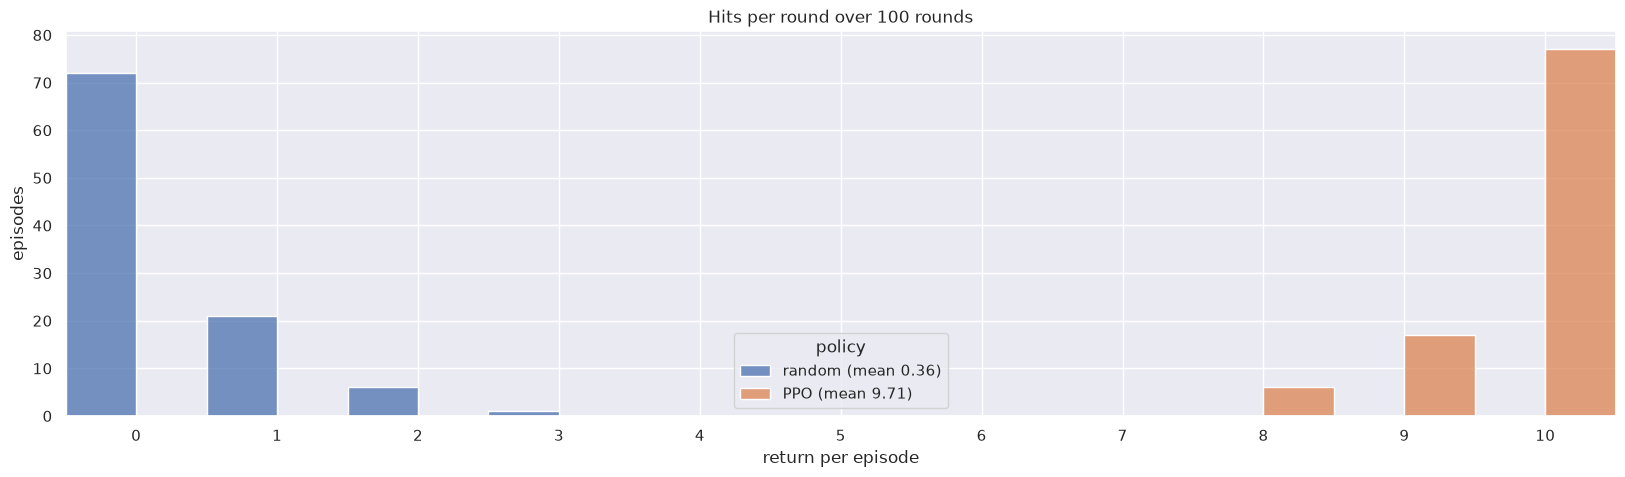

In [14]:
# Plot the hits per round of both policies.
returns_by_policy = {"random": random_returns, "PPO": trained_returns}
title = f"Hits per round over {n_rounds} rounds"
utils.plot_returns(returns_by_policy, n_shots, title)

**Guided usage**
- Set `total_timesteps` to 2048 in Cell 4.2 and rerun Parts 4 and 5
  - Observe the `PPO` bars spread to the left of 10

**Implementation** `utils.plot_returns()`
- Builds one row per round, labeled with its policy and the mean of that policy
- Draws a `seaborn` histogram with one bin per number of hits, and the policies
  side by side

## Conclusion

- The trained agent hits 9.71 targets per round, while random aims stay close to
  the 0.4 hits per round expected by chance (measured 0.36)
- Each shot is independent of the previous ones, so the task isolates the
  workflow:
  - Write the env
  - Check it with `check_env()`
  - Measure a baseline
  - Train
  - Compare on the same seeded rounds
- What to try next:
  - A larger grid, e.g., `grid_size = 10`
  - A smaller budget in Cell 4.2
  - `sb3.DQN` instead of `sb3.PPO` in Cell 4.1